&nbsp;

&nbsp;

## Survey: Antisense lncRNA pairs

&nbsp;

### BackGround

- 

&nbsp;

In [1]:
import re
import os
import pathlib
import datetime
import subprocess
import polars as pl
from IPython.display import display
from IPython.display import Image
from pygenometracks.readGtf import ReadGtf

pl.Config.set_fmt_str_lengths(200)
os.environ["POLARS_MAX_THREADS"] = "16"

In [2]:
execute_date = datetime.datetime.now().strftime("%y%m%d")  # noqa: DTZ005
print(f"Execute Date: {execute_date}")

Execute Date: 261020


&nbsp;

&nbsp;

## Prepare HN-score + fanta.bio

In [3]:
HNscore_all_fantabio = pl.read_parquet(
    "../../../out/fantabio/parquet_file/HNscore_transcript_all_fantabio_v261001.parquet"
).filter(
    pl.col("cre_id").is_not_null() # fanta.bio の CRE が紐づかなかった場合は、今回は考慮しない
)

pl.Config.set_tbl_rows(2)
display(HNscore_all_fantabio)

transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000309758.6""",352,17,37,335,232,4,15,228,"""HSPA6""","""HGNC:5239""","""protein_coding""","""ENSG00000173110.8""","[""basic"", ""Ensembl_canonical"", … ""CCDS""]","""+""",6,null,null,null,"""ensembl_havana_gene_homo_sapiens""","[""MANE_select""]",1,"""FCHS_28105""","""chr1""",161523745,"""161524487""","""cp1@HSPA6""","[""GQ891451""]","""0""",53,"[{""EH38E2843853"",""pELS""}, {""EH38E2843855"",""PLS""}, {""EH38E3981533"",""pELS""}]","[{""STAG2"",4103,[{""SRX9975614"",4103}, {""SRX9975613"",3500}, {""SRX26159208"",562}]}, {""HSF1"",4038,[{""SRX16646095"",4038}, {""SRX16646111"",3572}, … {""SRX13845684"",554}]}, … {""GABPA"",500,[{""SRX2635792"",500}]}]","[{""HS_00013400"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}, {""HS_00013401"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}, … {""HS_00013403"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}]",null,null,0.982111,"""PLA""","""204,0,0""","""red"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000549545.1""",11,265,130,-254,8,174,69,-166,"""COQ10A""","""HGNC:26515""","""retained_intron""","""ENSG00000135469.15""",[],"""+""",0,null,null,null,"""ensembl_havana_gene_homo_sapiens""",null,0,"""FCHS_96252""","""chr12""",56268140,"""56268446""","""cp6@COQ10A""","[""ENST00000549545.1""]","""-23""",-23,"[{""EH38E4064794"",""pELS""}]",null,"[{""HS_00173371"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}, {""HS_02053667"",""Thyroid Gland"",""Thyroid gland"",""Others"",""gkmSVM""}]",null,null,-0.368421,"""ELA""","""255,202,74""","""yellow"""


&nbsp;

&nbsp;

## Prepare: ENCODE-rE2G Result (Heat Stress)

In [4]:
encode_rE2G_hs_result = pl.read_parquet(
    "../../../out/ENCODE_rE2G/parquet_file/encode_re2g_hs_join_v261003.parquet"
).filter(
    pl.col("isSelfPromoter") == False
)


encode_rE2G_hs_result_unique_count = encode_rE2G_hs_result.group_by(
    "cre_id",
    "cre_name",
    "fantabio_cre_class",
    "target_cre_id",
    "target_cre_name",
    "target_fantabio_cre_class"
).agg(
    pl.col("re2g_dataset").unique().alias("re2g_dataset"),
    pl.col("re2g_dataset").n_unique().alias("re2g_dataset_count"),
    pl.col("enhancer_cre_overlap_frac_of_fantabio_cre").alias("enhancer_cre_overlap_frac_of_fantabio_cre"),
    pl.col("enhancer_cre_overlap_frac_of_fantabio_cre").min().alias("enhancer_cre_overlap_frac_of_fantabio_cre_min"),
    pl.col("enhancer_cre_overlap_frac_of_fantabio_cre").max().alias("enhancer_cre_overlap_frac_of_fantabio_cre_max"),
    pl.col("enhancer_cre_overlap_frac_of_fantabio_cre").mean().alias("enhancer_cre_overlap_frac_of_fantabio_cre_mean"), # 該当するデータセットで同定された enhancer と fantabio の CRE の重複率の平均値

    pl.col("ENCODE-rE2G.Score").alias("ENCODE-rE2G.Score"),
    pl.col("ENCODE-rE2G.Score").min().alias("ENCODE-rE2G.Score_min"),
    pl.col("ENCODE-rE2G.Score").max().alias("ENCODE-rE2G.Score_max"),
    pl.col("ENCODE-rE2G.Score").mean().alias("ENCODE-rE2G.Score_mean"), # 該当するデータセットで同定された enhancer と target promoter の相互作用のスコアの平均値

    # pl.col("ENCODE-rE2G.Score").quantile(0.25).alias("ENCODE-rE2G.Score_q1"),
    # pl.col("ENCODE-rE2G.Score").median().alias("ENCODE-rE2G.Score_median"),
    # pl.col("ENCODE-rE2G.Score").quantile(0.75).alias("ENCODE-rE2G.Score_q3"),
    # pl.col("ENCODE-rE2G.Score").std().alias("ENCODE-rE2G.Score_std"),
).sort(
    by=["re2g_dataset_count"],
    descending=True
)

print(f"ENCODE-rE2G enhancer - target region interaction unique pair count (fanta.bio cre level): {encode_rE2G_hs_result_unique_count.select(['cre_id', 'target_cre_id']).n_unique()}")
display(encode_rE2G_hs_result_unique_count)

ENCODE-rE2G enhancer - target region interaction unique pair count (fanta.bio cre level): 368398


cre_id,cre_name,fantabio_cre_class,target_cre_id,target_cre_name,target_fantabio_cre_class,re2g_dataset,re2g_dataset_count,enhancer_cre_overlap_frac_of_fantabio_cre,enhancer_cre_overlap_frac_of_fantabio_cre_min,enhancer_cre_overlap_frac_of_fantabio_cre_max,enhancer_cre_overlap_frac_of_fantabio_cre_mean,ENCODE-rE2G.Score,ENCODE-rE2G.Score_min,ENCODE-rE2G.Score_max,ENCODE-rE2G.Score_mean
str,str,str,str,str,str,list[str],u32,list[f64],f64,f64,f64,list[f64],f64,f64,f64
"""FCHS_337197""","""FCHS_337197""","""PLA""","""FCHS_337195""","""cp1@LMNB1""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[0.791139, 0.791139, … 0.791139]",0.772152,1.0,0.87014,"[0.915351, 0.931397, … 0.94268]",0.735602,0.970786,0.923106
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""FCHS_587581""","""FCHS_587581""","""ELA""","""FCHS_427348""","""cp6@TNC""","""PLA""","[""GSE267931_HUVEC_39C_120min""]",1,[1.0],1.0,1.0,1.0,[0.490011],0.490011,0.490011,0.490011


&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## Preparation: antisense transcript pair

- [antisense RNA process notebook](../06_transcript_characterization/06_5_antisense_RNA.ipynb) で作成したファイルを使用する
- GENCODE release 49 に紐づいている `tag` の選抜したリストでフィルタリング済み

In [5]:
bedfile_intersect_antisense_join = pl.read_parquet(
    "../../../out/transcript_classification/antisense_transcript/antisense_transcript_join_HNscore_fantabio_v261010.parquet"
)

display(bedfile_intersect_antisense_join)

chr_a,start_a,end_a,transcript_id_a,strand_a,chr_b,start_b,end_b,transcript_id_b,strand_b,num_match,frac_match_a,frac_match_b,gene_id_a,gene_symbol_a,transcript_type_a,HN2_a,HN2_stranded_a,cre_info_a,n_cre_a,gene_id_b,gene_symbol_b,transcript_type_b,HN2_b,HN2_stranded_b,cre_info_b,n_cre_b,n_shared_cre,n_shared_cre_ELA,n_shared_cre_PLA
str,i64,i64,str,str,str,i64,i64,str,str,i64,f64,f64,str,str,str,i64,i64,list[struct[2]],u32,str,str,str,i64,i64,list[struct[2]],u32,u32,u32,u32
"""chr1""",765078,827475,"""ENST00000743835.1""","""-""","""chr1""",778746,810063,"""ENST00000412115.2""","""+""",31317,0.501899,1.0,"""ENSG00000225880.7""","""LINC00115""","""lncRNA""",-6,-1,"[{""FCHS_25"",""ELA""}, {""FCHS_26"",""PLA""}]",2,"""ENSG00000237491.11""","""LINC01409""","""lncRNA""",9,12,"[{""FCHS_19"",""PLA""}, {""FCHS_20"",""ELA""}]",2,0,0,0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""chrX""",156023366,156025666,"""ENST00000496301.6""","""+""","""chrX""",156021995,156025666,"""ENST00000728197.1""","""-""",2300,1.0,0.626532,"""ENSG00000182484.15""","""WASH6P""","""retained_intron""",5,4,"[{""FCHS_446875"",""ELA""}]",1,"""ENSG00000295135.1""",null,"""lncRNA""",0,2,"[{""FCHS_593846"",""ELA""}]",1,0,0,0


In [6]:
# Canonical order so A-B and B-A collapse to one label.
pair_labels = (
    bedfile_intersect_antisense_join.select(
        pl.min_horizontal("transcript_id_a", "transcript_id_b").alias("id_lo"),
        pl.max_horizontal("transcript_id_a", "transcript_id_b").alias("id_hi"),
    )
    .unique(maintain_order=True)
    .select(pl.format("{} - {}", pl.col("id_lo"), pl.col("id_hi")).alias("pair"))
)

print(pair_labels.height)
pl.Config.set_tbl_rows(2)
display(pair_labels)

49887


pair
str
"""ENST00000412115.2 - ENST00000743835.1"""
…
"""ENST00000496301.6 - ENST00000728197.1"""


&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 4. UP-UP (stringent)

- 両方の transcript が HN-score (stranded) >= 100 である場合をフィルタリング
- 注目しやすい transcript pair を探すための簡単な条件

In [7]:
antisense_up_up = bedfile_intersect_antisense_join.filter(
    (pl.col("HN2_stranded_a") >= 100) & (pl.col("HN2_stranded_b") >= 100)
).sort(
    by=["HN2_stranded_a", "HN2_stranded_b"],
    descending=[True, True]
)

pl.Config.set_tbl_rows(32)
display(antisense_up_up)

chr_a,start_a,end_a,transcript_id_a,strand_a,chr_b,start_b,end_b,transcript_id_b,strand_b,num_match,frac_match_a,frac_match_b,gene_id_a,gene_symbol_a,transcript_type_a,HN2_a,HN2_stranded_a,cre_info_a,n_cre_a,gene_id_b,gene_symbol_b,transcript_type_b,HN2_b,HN2_stranded_b,cre_info_b,n_cre_b,n_shared_cre,n_shared_cre_ELA,n_shared_cre_PLA
str,i64,i64,str,str,str,i64,i64,str,str,i64,f64,f64,str,str,str,i64,i64,list[struct[2]],u32,str,str,str,i64,i64,list[struct[2]],u32,u32,u32,u32
"""chr17""",75135247,75154243,"""ENST00000476258.5""","""-""","""chr17""",75131088,75149037,"""ENST00000752388.1""","""+""",13790,0.725942,0.768288,"""ENSG00000189159.17""","""JPT1""","""protein_coding""",178,126,"[{""FCHS_506296"",""ELA""}, {""FCHS_182264"",""ELA""}, {""FCHS_182265"",""PLA""}]",3,"""ENSG00000298000.1""",null,"""lncRNA""",119,113,"[{""FCHS_182246"",""ELA""}, {""FCHS_182247"",""PLA""}, … {""FCHS_182249"",""PLA""}]",4,0,0,0
"""chr17""",75135285,75153293,"""ENST00000482348.5""","""-""","""chr17""",75131088,75149037,"""ENST00000752388.1""","""+""",13752,0.763661,0.766171,"""ENSG00000189159.17""","""JPT1""","""protein_coding""",197,116,"[{""FCHS_182259"",""ELA""}, {""FCHS_506295"",""ELA""}, … {""FCHS_182264"",""ELA""}]",5,"""ENSG00000298000.1""",null,"""lncRNA""",119,113,"[{""FCHS_182246"",""ELA""}, {""FCHS_182247"",""PLA""}, … {""FCHS_182249"",""PLA""}]",4,0,0,0
"""chr17""",75131088,75149037,"""ENST00000752388.1""","""+""","""chr17""",75135247,75154243,"""ENST00000476258.5""","""-""",13790,0.768288,0.725942,"""ENSG00000298000.1""",null,"""lncRNA""",119,113,"[{""FCHS_182246"",""ELA""}, {""FCHS_182247"",""PLA""}, … {""FCHS_182249"",""PLA""}]",4,"""ENSG00000189159.17""","""JPT1""","""protein_coding""",178,126,"[{""FCHS_506296"",""ELA""}, {""FCHS_182264"",""ELA""}, {""FCHS_182265"",""PLA""}]",3,0,0,0
"""chr17""",75131088,75149037,"""ENST00000752388.1""","""+""","""chr17""",75135285,75153293,"""ENST00000482348.5""","""-""",13752,0.766171,0.763661,"""ENSG00000298000.1""",null,"""lncRNA""",119,113,"[{""FCHS_182246"",""ELA""}, {""FCHS_182247"",""PLA""}, … {""FCHS_182249"",""PLA""}]",4,"""ENSG00000189159.17""","""JPT1""","""protein_coding""",197,116,"[{""FCHS_182259"",""ELA""}, {""FCHS_506295"",""ELA""}, … {""FCHS_182264"",""ELA""}]",5,0,0,0


In [8]:
# Canonical order so A-B and B-A collapse to one label.
pair_labels = (
    antisense_up_up.select(
        pl.min_horizontal("transcript_id_a", "transcript_id_b").alias("id_lo"),
        pl.max_horizontal("transcript_id_a", "transcript_id_b").alias("id_hi"),
    )
    .unique(maintain_order=True)
    .select(pl.format("{} - {}", pl.col("id_lo"), pl.col("id_hi")).alias("pair"))
)

print(pair_labels.height)
display(pair_labels)

2


pair
str
"""ENST00000476258.5 - ENST00000752388.1"""
"""ENST00000482348.5 - ENST00000752388.1"""


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## Case 1: JPT1 - lncRNA transcript pair

- お互いの transcript で、最もTSSに近い シスエレメントのみを可視化することに決定！

In [9]:
JPT1_antisense = HNscore_all_fantabio.filter(
    (pl.col("transcript_id").is_in(antisense_up_up.get_column("transcript_id_a").unique().implode()))
    | (pl.col("transcript_id").is_in(antisense_up_up.get_column("transcript_id_b").unique().implode()))
)

pl.Config.set_tbl_rows(2)
display(JPT1_antisense)

transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000482348.5""",225,28,153,197,129,13,109,116,"""JPT1""","""HGNC:14569""","""protein_coding""","""ENSG00000189159.17""","[""alternative_5_UTR"", ""basic"", ""CCDS""]","""-""",3,null,null,null,"""ensembl_havana_gene_homo_sapiens""","[""alternative 5' UTR""]",1,"""FCHS_182259""","""chr17""",75152686,"""75152838""","""cp4@JPT1""","[""ENST00000482348.5"", ""NM_001288610.1"", ""AK308253""]","""-455""",-455,"[{""EH38E3243128"",""pELS""}]",null,"[{""HS_00234500"",""Small Intestine"",""Small intestine"",""Intestine"",""SVM""}, {""HS_00234501"",""Pancreas"",""Pancreas"",""Pancreas"",""SVM""}]",null,null,-0.6,"""ELA""","""255,202,74""","""yellow"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000752388.1""",171,52,183,119,132,19,100,113,null,null,"""lncRNA""","""ENSG00000298000.1""","[""TAGENE""]","""+""",1,"""URS0002A5425C""","""ENSEMBL_GENCODE""",null,"""havana_tagene_homo_sapiens""","[""CLS3 project""]",1,"""FCHS_182249""","""chr17""",75131554,"""75132056""","""cp2@NT5C""","[""ENST00000876511.1"", ""ENST00000245552.7"", … ""CU692564""]","""0""",-465,"[{""EH38E1885628"",""PLS""}, {""EH38E3243102"",""pELS""}]","[{""CTCF"",4411,[{""SRX10976008"",4411}, {""SRX8622035"",4158}, … {""SRX13007612"",505}]}, {""NRF1"",4193,[{""SRX2424732"",4193}, {""SRX2424029"",4182}, … {""SRX23881992"",516}]}, … {""TOX4"",509,[{""SRX9785101"",509}]}]",null,"[{""hg19::chr17:73127799..73127806,-;hg_168037.1"",""p6@NT5C""}, {""hg19::chr17:73127808..73127821,-;hg_168038.1"",""p2@NT5C""}, … {""hg19::chr17:73127900..73127911,-;hg_168040.1"",""p5@NT5C""}]",null,-0.971176,"""PLA""","""0,0,204""","""blue"""


In [10]:
# For Visualization
JPT1_antisense_simple = JPT1_antisense.select(
    "transcript_id",
    "cre_id",
    "cre_name",
    "transcript_distance",
    "HN2",
    "HN2_stranded",
    "gene_id",
    "gene_symbol",
    "HGNC_ID",
    "transcript_type",
    "RNACentral_ID"
).unique(subset=["transcript_id", "cre_id"], maintain_order=True).filter(
    pl.col("transcript_distance").abs()
    == pl.col("transcript_distance").abs().min().over("transcript_id")
)

pl.Config.set_tbl_rows(12)
display(JPT1_antisense_simple)

transcript_id,cre_id,cre_name,transcript_distance,HN2,HN2_stranded,gene_id,gene_symbol,HGNC_ID,transcript_type,RNACentral_ID
str,str,str,i64,i64,i64,str,str,str,str,str
"""ENST00000482348.5""","""FCHS_182261""","""cp7@JPT1""",2,197,116,"""ENSG00000189159.17""","""JPT1""","""HGNC:14569""","""protein_coding""",null
"""ENST00000476258.5""","""FCHS_182264""","""cp2@JPT1""",0,178,126,"""ENSG00000189159.17""","""JPT1""","""HGNC:14569""","""protein_coding""",null
"""ENST00000752388.1""","""FCHS_182247""","""cp1@NT5C""",0,119,113,"""ENSG00000298000.1""",null,null,"""lncRNA""","""URS0002A5425C"""


In [11]:
JPT1_cre = JPT1_antisense.filter(
    pl.col("gene_id") == "ENSG00000189159.17"
).select("cre_id")

ENSG00000298000_cre = JPT1_antisense.filter(
    pl.col("gene_id") == "ENSG00000298000.1"
).select("cre_id")

pl.Config.set_tbl_rows(2)
display(JPT1_cre)
display(ENSG00000298000_cre)

cre_id
str
"""FCHS_182259"""
…
"""FCHS_182265"""


cre_id
str
"""FCHS_182246"""
…
"""FCHS_182249"""


In [12]:
# Case 0: どの CRE の "target_cre_id" になっているかを確認
JPT1_active_cre_target = encode_rE2G_hs_result_unique_count.filter(
    (pl.col("target_cre_id").is_in(JPT1_cre.get_column("cre_id").unique().implode()))
).sort(
    by=["cre_id"],
    descending=True
)

JPT_antisense_active_cre = encode_rE2G_hs_result_unique_count.filter(
    pl.col("target_cre_id").is_in(ENSG00000298000_cre.get_column("cre_id").unique().implode())
).sort(
    by=["cre_id"],
    descending=True
)

# 共通する CRE を確認
shared_cre_id = (
    JPT1_active_cre_target.select("cre_id").unique()
    .join(
        JPT_antisense_active_cre.select("cre_id").unique(),
        on="cre_id",
        how="inner",
    )
    .sort("cre_id")
)

JPT1_active_cre_target_filtered = JPT1_active_cre_target.filter(
    pl.col("cre_id").is_in(shared_cre_id.get_column("cre_id").unique().implode())
)

JPT_antisense_active_cre_filtered = JPT_antisense_active_cre.filter(
    pl.col("cre_id").is_in(shared_cre_id.get_column("cre_id").unique().implode())
)

pl.Config.set_tbl_rows(6)
print(shared_cre_id.height)
display(JPT1_active_cre_target_filtered)
display(JPT_antisense_active_cre_filtered)

6


cre_id,cre_name,fantabio_cre_class,target_cre_id,target_cre_name,target_fantabio_cre_class,re2g_dataset,re2g_dataset_count,enhancer_cre_overlap_frac_of_fantabio_cre,enhancer_cre_overlap_frac_of_fantabio_cre_min,enhancer_cre_overlap_frac_of_fantabio_cre_max,enhancer_cre_overlap_frac_of_fantabio_cre_mean,ENCODE-rE2G.Score,ENCODE-rE2G.Score_min,ENCODE-rE2G.Score_max,ENCODE-rE2G.Score_mean
str,str,str,str,str,str,list[str],u32,list[f64],f64,f64,f64,list[f64],f64,f64,f64
"""FCHS_506274""","""FCHS_506274""","""ELA""","""FCHS_182265""","""cp1@JPT1""","""PLA""","[""GSE267931_HUVEC_39C_120min""]",1,[0.952381],0.952381,0.952381,0.952381,[0.208172],0.208172,0.208172,0.208172
"""FCHS_506273""","""FCHS_506273""","""ELA""","""FCHS_182265""","""cp1@JPT1""","""PLA""","[""GSE154744_K562_42C_30min"", ""GSE154744_K562_42C_30min_intact_hic"", ""GSE267931_HUVEC_39C_120min""]",3,"[0.97551, 0.97551, 1.0]",0.97551,1.0,0.983673,"[0.221308, 0.633988, 0.208172]",0.208172,0.633988,0.354489
"""FCHS_182187""","""FCHS_182187""","""PLA""","""FCHS_182265""","""cp1@JPT1""","""PLA""","[""GSE154744_K562_42C_12_5min"", ""GSE154744_K562_42C_30min"", … ""GSE267931_HUVEC_39C_120min""]",4,"[1.0, 1.0, … 1.0]",1.0,1.0,1.0,"[0.221402, 0.221308, … 0.208172]",0.208172,0.633988,0.321218
"""FCHS_182186""","""FCHS_182186""","""ELA""","""FCHS_182265""","""cp1@JPT1""","""PLA""","[""GSE154744_K562_42C_12_5min"", ""GSE154744_K562_42C_30min"", … ""GSE267931_HUVEC_39C_120min""]",4,"[1.0, 1.0, … 1.0]",1.0,1.0,1.0,"[0.221402, 0.221308, … 0.208172]",0.208172,0.633988,0.321218
"""FCHS_182185""","""FCHS_182185""","""PLA""","""FCHS_182265""","""cp1@JPT1""","""PLA""","[""GSE154744_K562_42C_12_5min"", ""GSE154744_K562_42C_30min"", … ""GSE267931_HUVEC_39C_120min""]",4,"[1.0, 1.0, … 1.0]",1.0,1.0,1.0,"[0.221402, 0.221308, … 0.208172]",0.208172,0.633988,0.321218
"""FCHS_182184""","""FCHS_182184""","""ELA""","""FCHS_182265""","""cp1@JPT1""","""PLA""","[""GSE154744_K562_42C_12_5min"", ""GSE154744_K562_42C_30min"", … ""GSE267931_HUVEC_39C_120min""]",4,"[1.0, 1.0, … 0.625821]",0.625821,1.0,0.906455,"[0.221402, 0.221308, … 0.208172]",0.208172,0.633988,0.321218


cre_id,cre_name,fantabio_cre_class,target_cre_id,target_cre_name,target_fantabio_cre_class,re2g_dataset,re2g_dataset_count,enhancer_cre_overlap_frac_of_fantabio_cre,enhancer_cre_overlap_frac_of_fantabio_cre_min,enhancer_cre_overlap_frac_of_fantabio_cre_max,enhancer_cre_overlap_frac_of_fantabio_cre_mean,ENCODE-rE2G.Score,ENCODE-rE2G.Score_min,ENCODE-rE2G.Score_max,ENCODE-rE2G.Score_mean
str,str,str,str,str,str,list[str],u32,list[f64],f64,f64,f64,list[f64],f64,f64,f64
"""FCHS_506274""","""FCHS_506274""","""ELA""","""FCHS_182249""","""cp2@NT5C""","""PLA""","[""GSE267931_HUVEC_39C_120min""]",1,[0.952381],0.952381,0.952381,0.952381,[0.19448],0.19448,0.19448,0.19448
"""FCHS_506273""","""FCHS_506273""","""ELA""","""FCHS_182249""","""cp2@NT5C""","""PLA""","[""GSE267931_HUVEC_39C_120min""]",1,[1.0],1.0,1.0,1.0,[0.19448],0.19448,0.19448,0.19448
"""FCHS_182187""","""FCHS_182187""","""PLA""","""FCHS_182249""","""cp2@NT5C""","""PLA""","[""GSE267931_HUVEC_39C_120min""]",1,[1.0],1.0,1.0,1.0,[0.19448],0.19448,0.19448,0.19448
"""FCHS_182186""","""FCHS_182186""","""ELA""","""FCHS_182249""","""cp2@NT5C""","""PLA""","[""GSE267931_HUVEC_39C_120min""]",1,[1.0],1.0,1.0,1.0,[0.19448],0.19448,0.19448,0.19448
"""FCHS_182185""","""FCHS_182185""","""PLA""","""FCHS_182249""","""cp2@NT5C""","""PLA""","[""GSE267931_HUVEC_39C_120min""]",1,[1.0],1.0,1.0,1.0,[0.19448],0.19448,0.19448,0.19448
"""FCHS_182184""","""FCHS_182184""","""ELA""","""FCHS_182249""","""cp2@NT5C""","""PLA""","[""GSE267931_HUVEC_39C_120min""]",1,[0.625821],0.625821,0.625821,0.625821,[0.19448],0.19448,0.19448,0.19448


&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## Visualization (Antisense lncRNA)

### 表示領域

- UCSC Genome Browser で決めた window をそのまま使う
- [UCSC Genome Browser Result](https://genome.ucsc.edu/cgi-bin/hgTracks?db=hg38&lastVirtModeType=default&lastVirtModeExtraState=&virtModeType=default&virtMode=0&nonVirtPosition=&position=chr17%3A75129796%2D75156795&hgsid=4212371127_R6AFCLL6Z0CDy2omdi5UasyWoEMz)
- Region: chr17:75,129,796-75,156,795

&nbsp;

### Related Dataframe

1. `JPT1_antisense_simple`（JPT1 の `ENST00000476258.5` と `ENST00000482348.5`、対向する lncRNA `ENST00000752388.1`。gene symbol は未付与なので `ENSG00000298000.1`。各 transcript について、転写開始点から最も近い fanta.bio CRE だけを描く。ENCODE-rE2G は描かない）


In [13]:
# Plot window chosen on the UCSC Genome Browser (hg38).
# https://genome.ucsc.edu/cgi-bin/hgTracks?db=hg38&position=chr17%3A75129796-75156795

REGION_CHROM = "chr17"
REGION_START = 75_129_796
REGION_END = 75_156_795

repo_root = pathlib.Path("../../../").resolve()
gtf_full = repo_root / "Data/Database/GENCODE_v49/gencode.v49.chr_patch_hapl_scaff.annotation.gtf"
cre_full = repo_root / "Data/Database/fantabio/human-CREv1.2.1.hg38.cre-peaks.bed"
out_dir = (
    repo_root
    / "out/transcript_survey/pygenometracks"
    / f"JPT1_{REGION_CHROM}_{REGION_START}_{REGION_END}"
)
out_dir.mkdir(parents=True, exist_ok=True)

print(out_dir)

/workspaces/HS_human_ncRNA/out/transcript_survey/pygenometracks/JPT1_chr17_75129796_75156795


In [14]:
# Closest CRE of each transcript, already filtered in JPT1_antisense_simple.
# fanta.bio BED has 11 columns; pyGenomeTracks reads itemRgb only up to BED9.
# Column 4 is replaced by cre_name (e.g. cp2@JPT1) so the label shows the gene.
cre_ids = JPT1_antisense_simple.select("cre_id").unique(maintain_order=True)

cre_keep = pl.read_csv(
    cre_full,
    separator="\t",
    has_header=False,
    new_columns=[
        "chrom", "start", "end", "cre_id", "score", "strand",
        "thick_start", "thick_end", "item_rgb", "cre_name", "annot",
    ],
).join(cre_ids, on="cre_id", how="inner")

cre_bed9 = out_dir / "JPT1_cre.bed9.bed"
cre_keep.select(
    "chrom", "start", "end", "cre_name", "score", "strand",
    "thick_start", "thick_end", "item_rgb",
).write_csv(cre_bed9, separator="\t", include_header=False)

print(f"CRE intervals: {cre_keep.height}")
display(cre_keep.select("cre_id", "cre_name", "chrom", "start", "end"))

CRE intervals: 3


cre_id,cre_name,chrom,start,end
str,str,str,i64,i64
"""FCHS_182247""","""cp1@NT5C""","""chr17""",75130511,75131270
"""FCHS_182261""","""cp7@JPT1""","""chr17""",75153294,75153669
"""FCHS_182264""","""cp2@JPT1""","""chr17""",75153673,75154369


In [15]:
# Transcript models for the ids in JPT1_antisense_simple.
# A gtf track has one color, so convert to BED12 and color only by strand.
# Use the gene symbol when it exists, otherwise the Ensembl gene id.
tx_info = (
    JPT1_antisense_simple.select(
        "transcript_id",
        pl.when(pl.col("gene_symbol").is_not_null())
        .then(pl.col("gene_symbol"))
        .otherwise(pl.col("gene_id"))
        .alias("group"),
    )
    .unique(subset="transcript_id", maintain_order=True)
)

# Plus strand in blue, minus strand in orange.
STRAND_RGB = {
    "+": "0,114,178",
    "-": "230,120,0",
}
tx_group = dict(zip(tx_info["transcript_id"], tx_info["group"]))

# BED12 blocks must span the whole transcript, so pull full models from the GTF.
gtf_header = subprocess.run(
    ["grep", "^#", str(gtf_full)],
    check=True,
    capture_output=True,
    text=True,
)
tx_gtf_full = out_dir / "JPT1_transcripts.full.gtf"
tx_patterns = "".join(f'transcript_id "{tx_id}";\n' for tx_id in sorted(tx_group))
tx_full_hits = subprocess.run(
    ["grep", "-F", "-f", "-", str(gtf_full)],
    input=tx_patterns,
    check=True,
    capture_output=True,
    text=True,
)
tx_gtf_full.write_text(gtf_header.stdout + tx_full_hits.stdout)

tx_bed12 = out_dir / "JPT1_transcripts.bed12.bed"
tx_found = set()
with tx_bed12.open("w") as handle_out:
    for tx in ReadGtf(str(tx_gtf_full), prefered_name="transcript_id", merge_transcripts=False):
        group = tx_group[tx.name]
        tx_found.add(tx.name)
        # Keep the gene name on every transcript so JPT1 and the antisense lncRNA stay readable.
        label = tx.name if group == tx.name else f"{tx.name} ({group})"
        handle_out.write(
            "\t".join(
                map(
                    str,
                    [
                        tx.chromosome, tx.start, tx.end, label, tx.score, tx.strand,
                        tx.thick_start, tx.thick_end, STRAND_RGB[tx.strand], tx.block_count,
                        ",".join(map(str, tx.block_sizes)),
                        ",".join(map(str, tx.block_starts)),
                    ],
                )
            )
            + "\n"
        )

print(f"transcripts in dataframe: {len(tx_group)}, written to BED12: {len(tx_found)}")
display(tx_info)

transcripts in dataframe: 3, written to BED12: 3


transcript_id,group
str,str
"""ENST00000482348.5""","""JPT1"""
"""ENST00000476258.5""","""JPT1"""
"""ENST00000752388.1""","""ENSG00000298000.1"""


INFO:pygenometracks.tracksClass:initialize 1. [spacer]
INFO:pygenometracks.tracksClass:initialize 2. [x-axis]
INFO:pygenometracks.tracksClass:initialize 3. [spacer]
INFO:pygenometracks.tracksClass:initialize 4. [fanta CRE]
100%|██████████| 3/3 [00:00<00:00, 31145.82it/s]
INFO:pygenometracks.tracksClass:initialize 5. [spacer]
INFO:pygenometracks.tracksClass:initialize 6. [transcripts]
100%|██████████| 3/3 [00:00<00:00, 37900.34it/s]
INFO:pygenometracks.tracksClass:time initializing track(s):
INFO:pygenometracks.tracksClass:0.005325794219970703
DEBUG:pygenometracks.tracksClass:Figure size in cm is 30.0 x 9.946808510638299. Dpi is set to 150

INFO:pygenometracks.tracksClass:plotting 1. [spacer]
INFO:pygenometracks.tracksClass:plotting 2. [x-axis]
INFO:pygenometracks.tracksClass:plotting 3. [spacer]
INFO:pygenometracks.tracksClass:plotting 4. [fanta CRE]
DEBUG:pygenometracks.tracks.GenomeTrack:ylim 3.38,-0.08
DEBUG:pygenometracks.tracks.GenomeTrack:ylim (np.float64(3.38), np.float64(-0.08)

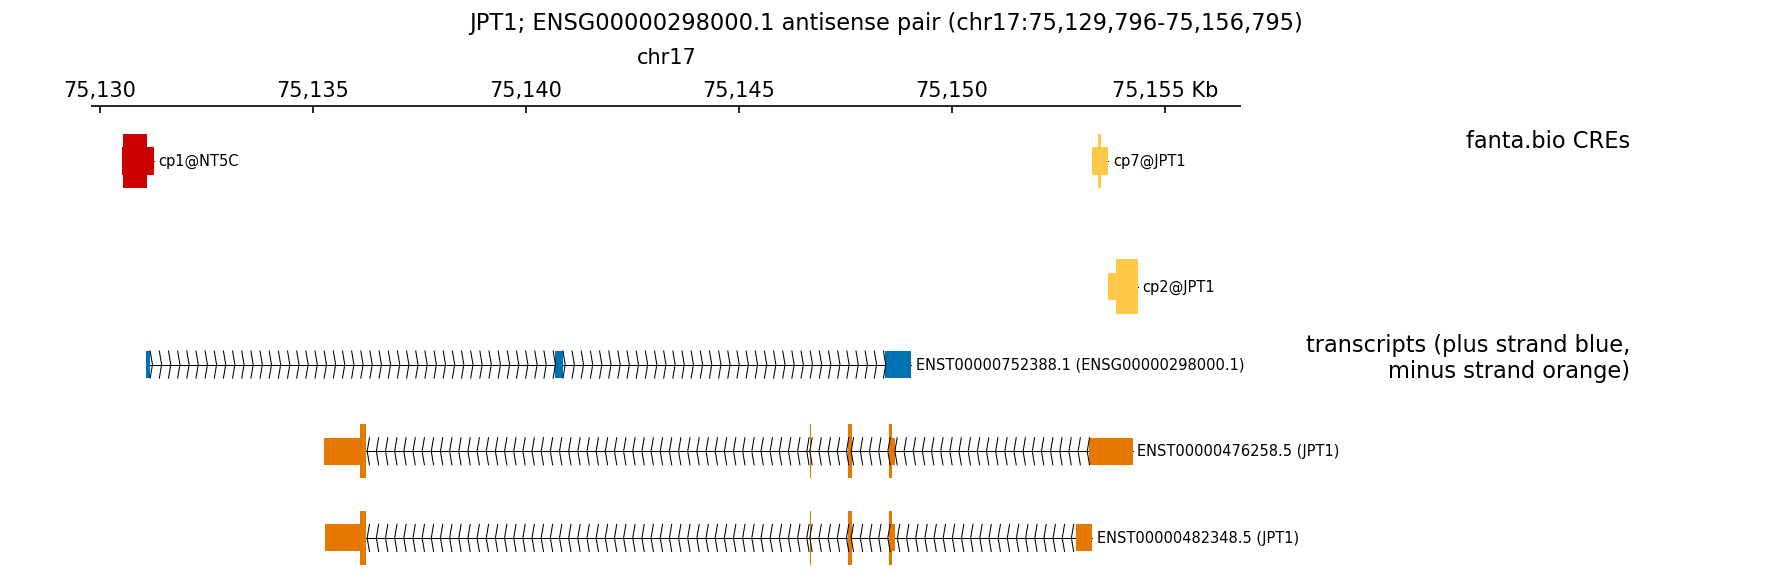

In [16]:
# CRE in the middle, transcript models at the bottom. This notebook has no ENCODE-rE2G arcs.
tracks_ini = out_dir / "JPT1_tracks.ini"
figure_png = out_dir / "JPT1_antisense.png"
gene_labels = tx_info.select("group").unique(maintain_order=True).to_series().to_list()
figure_title = (
    f"{'; '.join(gene_labels)} antisense pair "
    f"({REGION_CHROM}:{REGION_START:,}-{REGION_END:,})"
)
tracks_ini.write_text(
    f"""\
[spacer]
height = 0.5

[x-axis]
where = top
fontsize = 10

[spacer]
height = 0.15

[fanta CRE]
file = {cre_bed9.name}
title = fanta.bio CREs
file_type = bed
height = 3.2
color = bed_rgb
border_color = none
labels = true
fontsize = 7
style = UCSC
display = stacked

[spacer]
height = 0.25

[transcripts]
file = {tx_bed12.name}
title = transcripts (plus strand blue, minus strand orange)
file_type = bed
height = 4
color = bed_rgb
labels = true
all_labels_inside = true
fontsize = 7
style = UCSC
display = stacked
"""
)

# Mathtext draws digits with mathtext.rm, so both rm and it must be italic
# for gene symbols in the title to render fully italic.
mplrc = out_dir / "matplotlibrc"
mplrc.write_text(
    "mathtext.fontset : custom\n"
    "mathtext.rm : DejaVu Sans:italic\n"
    "mathtext.it : DejaVu Sans:italic\n"
)

# Stacked rows are spaced by BedTrack.row_scale, which is fixed at 2.3
# (the gene body is 1). A smaller value tightens only the gap.
# Patch it in a fresh process so the notebook kernel is left unchanged.
plot_code = """
from pygenometracks.tracks.BedTrack import BedTrack
from pygenometracks.plotTracks import main
import sys

_orig_bed_init = BedTrack.__init__

def _bed_init(self, *args, **kwargs):
    _orig_bed_init(self, *args, **kwargs)
    if self.properties.get("section_name", "").endswith("[transcripts]"):
        self.row_scale = 1.6

BedTrack.__init__ = _bed_init
main(sys.argv[1:])
"""
subprocess.run(
    [
        "python3",
        "-c",
        plot_code,
        "--tracks",
        str(tracks_ini),
        "--region",
        f"{REGION_CHROM}:{REGION_START}-{REGION_END}",
        "--width",
        "30",
        "--dpi",
        "150",
        "--trackLabelFraction",
        "0.25",
        "--trackLabelHAlign",
        "right",
        "--outFileName",
        str(figure_png),
        "--title",
        figure_title,
    ],
    check=True,
    cwd=out_dir,
    env={**os.environ, "MATPLOTLIBRC": str(mplrc)},
)
display(Image(filename=str(figure_png)))
